In [1]:
import sys
import neo4j
import pandas
import numpy
import scipy
import sklearn
import networkx
import matplotlib

print("Python  :", sys.version.split()[0])
print("neo4j   :", neo4j.__version__)
print("pandas  :", pandas.__version__)
print("numpy   :", numpy.__version__)
print("Lokasi  :", sys.prefix)   # harus mengarah ke folder myenv

Python  : 3.13.0
neo4j   : 6.4.1
pandas  : 3.0.6
numpy   : 2.5.4
Lokasi  : C:\Users\Acer\uts-graf\myenv


In [2]:
from getpass import getpass
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", getpass("Password Neo4j: "))

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()
print("Koneksi berhasil!")

Password Neo4j:  ········


Koneksi berhasil!


In [3]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )

def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

add_friend(driver, "Arthur", "Guinevere")
add_friend(driver, "Arthur", "Lancelot")
add_friend(driver, "Arthur", "Merlin")
print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


In [4]:
import pandas as pd

records, _, _ = driver.execute_query(
    "MATCH (a:Person)-[r:KNOWS]->(b:Person) RETURN a.name AS dari, type(r) AS relasi, b.name AS ke",
    database_="neo4j", routing_=RoutingControl.READ,
)
graf_df = pd.DataFrame([r.data() for r in records])
graf_df

,dari,relasi,ke
0,Arthur,KNOWS,Guinevere
1,Arthur,KNOWS,Lancelot
2,Arthur,KNOWS,Merlin


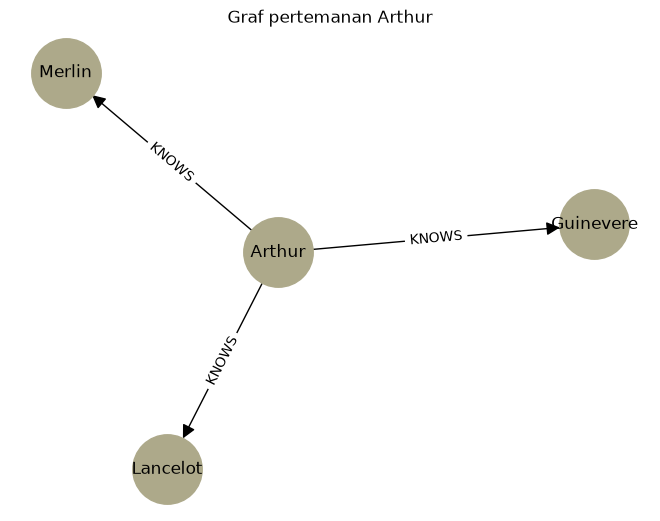

In [5]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()
for _, r in graf_df.iterrows():
    G.add_edge(r["dari"], r["ke"], label=r["relasi"])

pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, with_labels=True, node_size=2500, node_color="#ADA98A", arrows=True, arrowsize=20)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "label"))
plt.title("Graf pertemanan Arthur")
plt.show()

In [6]:
import os
for f in sorted(os.listdir("data")):
    print(f"{f:35s} {os.path.getsize(os.path.join('data', f))/1e6:10.1f} MB")

category_tree.csv                          0.0 MB
events.csv                                94.2 MB
item_properties_part1.csv                484.3 MB
item_properties_part2.csv                408.9 MB


In [7]:
df = pd.read_csv("data/events.csv")
df["dt"] = pd.to_datetime(df["timestamp"], unit="ms")

print("Jumlah baris       :", f"{len(df):,}")
print("Rentang tanggal    :", df["dt"].min(), "->", df["dt"].max())
print("Visitor unik       :", f"{df['visitorid'].nunique():,}")
print("Item unik          :", f"{df['itemid'].nunique():,}")
print("\nJenis event:")
print(df["event"].value_counts())
df.head()

Jumlah baris       : 2,756,101
Rentang tanggal    : 2015-05-03 03:00:04.384000 -> 2015-09-18 02:59:47.788000
Visitor unik       : 1,407,580
Item unik          : 235,061

Jenis event:
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64


,timestamp,visitorid,event,itemid,transactionid,dt
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164
2,1433221999827,111016,view,318965,NaN,2015-06-02 05:13:19.827
3,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914
4,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106


**Bagian 2.1: Wrangling dan EDA**

No.1 Tentukan 2 periode waktu sebagai filter dari data interaksi. Kombinasi periode yang dipilih tiap mahasiswa

In [8]:
# Pilihan nomor 19 (Gresya)
P1 = ("2015-06-01", "2015-06-15")   # training: 01-15 Juni 2015
P2 = ("2015-08-01", "2015-08-15")   # testing : 01-15 Agustus 2015
print("P1:", P1)
print("P2:", P2)

P1: ('2015-06-01', '2015-06-15')
P2: ('2015-08-01', '2015-08-15')


In [9]:
# Kosongkan graf lama (bertahap)
total_dihapus = 0
with driver.session(database="neo4j") as s:
    while True:
        n = s.run("MATCH (n) WITH n LIMIT 10000 DETACH DELETE n RETURN count(*) AS c").single()["c"]
        if n == 0:
            break
        total_dihapus += n
print("Simpul dihapus:", f"{total_dihapus:,}")

rec, _, _ = driver.execute_query("MATCH (n) RETURN count(n) AS jumlah", database_="neo4j")
print("Sisa simpul:", rec[0]["jumlah"])   # harus 0

Simpul dihapus: 239,917
Sisa simpul: 0


No.2 Terapkan proses filter ini pada timestamp pada proses persiapan data, lalu simpan pada sebuah file .csv!

In [10]:
def ambil_periode(data, mulai, akhir):
    awal = pd.Timestamp(mulai)
    batas = pd.Timestamp(akhir) + pd.Timedelta(days=1)   # tanggal akhir ikut
    return data[(data["dt"] >= awal) & (data["dt"] < batas)]

p1 = ambil_periode(df, *P1).drop(columns="dt")
p2 = ambil_periode(df, *P2).drop(columns="dt")

os.makedirs("output", exist_ok=True)
P1_CSV = "output/events_p1_train.csv"
P2_CSV = "output/events_p2_test.csv"
p1.to_csv(P1_CSV, index=False)
p2.to_csv(P2_CSV, index=False)

for nama, d, p in [("P1", p1, P1), ("P2", p2, P2)]:
    print(f"{nama} {p}: {len(d):,} baris | visitor {d['visitorid'].nunique():,} | item {d['itemid'].nunique():,}")
    print(d["event"].value_counts().to_string(), "\n")

P1 ('2015-06-01', '2015-06-15'): 300,563 baris | visitor 160,017 | item 79,896
event
view           291122
addtocart        7110
transaction      2331 

P2 ('2015-08-01', '2015-08-15'): 265,509 baris | visitor 153,836 | item 76,078
event
view           256371
addtocart        7047
transaction      2091 



In [11]:
from tqdm.auto import tqdm

driver.execute_query(
    "CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE",
    database_="neo4j")
driver.execute_query(
    "CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE",
    database_="neo4j")

Q_VIEW = """
UNWIND $batch AS row
MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})
CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
"""
Q_CART = """
UNWIND $batch AS row
MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})
CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
"""
Q_BUY = """
UNWIND $batch AS row
MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})
CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
"""

def import_batch(tx, batch):
    views = [r for r in batch if r["event"] == "view"]
    carts = [r for r in batch if r["event"] == "addtocart"]
    buys  = [r for r in batch if r["event"] == "transaction"]
    if views: tx.run(Q_VIEW, batch=views)
    if carts: tx.run(Q_CART, batch=carts)
    if buys:  tx.run(Q_BUY,  batch=buys)
print("Fungsi impor siap.")

Fungsi impor siap.


In [12]:
rec, _, _ = driver.execute_query("MATCH (n) RETURN count(n) AS jumlah", database_="neo4j")
print("Jumlah simpul sekarang:", rec[0]["jumlah"])

Jumlah simpul sekarang: 0


In [13]:
batch_size = 10_000
total_rows = len(p1)
total_chunks = (total_rows // batch_size) + 1

chunks = pd.read_csv(P1_CSV, chunksize=batch_size)
with driver.session(database="neo4j") as session:
    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor batch"):
        chunk["transactionid"] = chunk["transactionid"].astype("Int64").astype("string").fillna("")
        session.execute_write(import_batch, chunk.to_dict(orient="records"))
print("Proses impor berhasil.")

Mengimpor batch:   0%|          | 0/31 [00:00<?, ?it/s]

Proses impor berhasil.


In [14]:
rec, _, _ = driver.execute_query(
    "MATCH (n) RETURN labels(n)[0] AS jenis, count(n) AS jumlah", database_="neo4j")
print("SIMPUL:", [r.data() for r in rec])

rec, _, _ = driver.execute_query(
    "MATCH ()-[r]->() RETURN type(r) AS relasi, count(r) AS jumlah", database_="neo4j")
print("RELASI:", [r.data() for r in rec])

SIMPUL: [{'jenis': 'Visitor', 'jumlah': 160017}, {'jenis': 'Item', 'jumlah': 79896}]
RELASI: [{'relasi': 'VIEWED', 'jumlah': 291122}, {'relasi': 'ADDED_TO_CART', 'jumlah': 7110}, {'relasi': 'BOUGHT', 'jumlah': 2331}]


No.3 Lakukan query untuk mendapatkan komposisi dari subgraph yang dibuat. Uraikan jenis simpul dan jumlah masing-masing simpul dengan Python API! Jelaskan CYPHER SQL yang digunakan!

In [15]:
Q_NODES = """
MATCH (n)
RETURN labels(n)[0] AS jenis_simpul, count(n) AS jumlah
ORDER BY jumlah DESC
"""
Q_RELS = """
MATCH ()-[r]->()
RETURN type(r) AS jenis_relasi, count(r) AS jumlah
ORDER BY jumlah DESC
"""

def run_df(query, **params):
    with driver.session(database="neo4j") as s:
        return pd.DataFrame(s.run(query, **params).data())

df_nodes = run_df(Q_NODES)
df_rels = run_df(Q_RELS)
display(df_nodes)
display(df_rels)

,jenis_simpul,jumlah
0,Visitor,160017
1,Item,79896


,jenis_relasi,jumlah
0,VIEWED,291122
1,ADDED_TO_CART,7110
2,BOUGHT,2331


No.4 Lakukan Vector Space Modelling (VSM) terhadap simpul yang diasumsikan sebagai User. Uraikan bagaimana
karakteristiknya (dimensi, shape, plot networkx, dst.)!

In [16]:
import numpy as np
import scipy.sparse as sp

W = {"VIEWED": 1.0, "ADDED_TO_CART": 3.0, "BOUGHT": 5.0}

Q_EDGES = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS u, i.itemId AS i, type(r) AS t, count(r) AS n
"""
edges = run_df(Q_EDGES)
edges["w"] = edges["n"] * edges["t"].map(W)
edges = edges.groupby(["u", "i"], as_index=False)["w"].sum()

user_ids, user_idx = np.unique(edges["u"].values, return_inverse=True)
item_ids, item_idx = np.unique(edges["i"].values, return_inverse=True)

X = sp.csr_matrix((edges["w"].values, (user_idx, item_idx)),
                  shape=(len(user_ids), len(item_ids)))
uid2row = {u: k for k, u in enumerate(user_ids)}
iid2col = {i: k for k, i in enumerate(item_ids)}

print("Matriks User-Item X:", X.shape, "| non-zero:", X.nnz)

Matriks User-Item X: (160017, 79896) | non-zero: 234959


In [17]:
def describe_vsm(M, nama, sumbu):
    n, d = M.shape
    per_vektor = np.diff(M.tocsr().indptr)
    print(f"=== VSM {nama} ===")
    print(f"Jumlah vektor        : {n:,}")
    print(f"Dimensi              : {d:,} ({sumbu})")
    print(f"Shape                : {M.shape}")
    print(f"Non-zero             : {M.nnz:,}")
    print(f"Density              : {M.nnz/(n*d):.8%}")
    print(f"Rata-rata non-zero/vektor: {per_vektor.mean():.2f} | median {np.median(per_vektor):.0f} | maks {per_vektor.max()}")
    print(f"Ukuran jika dense    : {n*d*8/1e9:,.1f} GB")

describe_vsm(X, "USER", "item")

=== VSM USER ===
Jumlah vektor        : 160,017
Dimensi              : 79,896 (item)
Shape                : (160017, 79896)
Non-zero             : 234,959
Density              : 0.00183781%
Rata-rata non-zero/vektor: 1.47 | median 1 | maks 358
Ukuran jika dense    : 102.3 GB


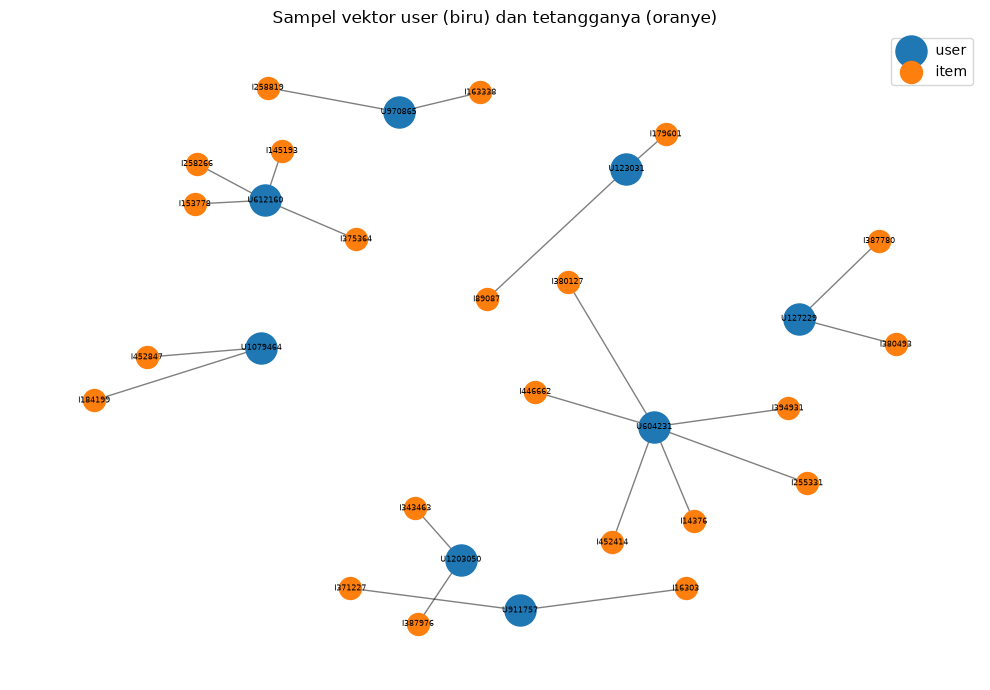

In [18]:
import networkx as nx
import matplotlib.pyplot as plt

def plot_sampel(pusat="user", n_pusat=8, maks_tetangga=6, seed=42):
    rng = np.random.default_rng(seed)
    M = X.tocsr() if pusat == "user" else X.T.tocsr()
    nama_p = user_ids if pusat == "user" else item_ids
    nama_t = item_ids if pusat == "user" else user_ids
    huruf_p, huruf_t = ("U", "I") if pusat == "user" else ("I", "U")

    derajat = np.diff(M.indptr)
    kandidat = np.where(derajat >= 2)[0]
    pilih = rng.choice(kandidat, size=n_pusat, replace=False)

    G = nx.Graph(); simpul_p, simpul_t = [], []
    for r in pilih:
        a, b = M.indptr[r], M.indptr[r + 1]
        p = f"{huruf_p}{nama_p[r]}"; simpul_p.append(p)
        pasangan = sorted(zip(M.indices[a:b], M.data[a:b]), key=lambda z: -z[1])[:maks_tetangga]
        for c, w in pasangan:
            t = f"{huruf_t}{nama_t[c]}"; simpul_t.append(t)
            G.add_edge(p, t, weight=w)

    pos = nx.spring_layout(G, seed=seed, k=0.6)
    plt.figure(figsize=(10, 7))
    nx.draw_networkx_nodes(G, pos, nodelist=simpul_p, node_color="tab:blue", node_size=500, label=pusat)
    nx.draw_networkx_nodes(G, pos, nodelist=list(set(simpul_t)), node_color="tab:orange", node_size=250,
                           label="item" if pusat == "user" else "user")
    nx.draw_networkx_edges(G, pos, alpha=0.5)
    nx.draw_networkx_labels(G, pos, font_size=6)
    plt.title(f"Sampel vektor {pusat} (biru) dan tetangganya (oranye)")
    plt.legend(); plt.axis("off"); plt.tight_layout()
    plt.savefig(f"output/plot_{pusat}.png", dpi=150)
    plt.show()

plot_sampel("user")

No.5 Lakukan VSM terhadap simpul yang diasumsikan sebagai Item. Uraikan bagaimana karakteristiknya (dimensi, shape, plot networkx, dst.)!

In [19]:
X_item = X.T.tocsr()          # item x user
describe_vsm(X_item, "ITEM", "user")

=== VSM ITEM ===
Jumlah vektor        : 79,896
Dimensi              : 160,017 (user)
Shape                : (79896, 160017)
Non-zero             : 234,959
Density              : 0.00183781%
Rata-rata non-zero/vektor: 2.94 | median 1 | maks 928
Ukuran jika dense    : 102.3 GB


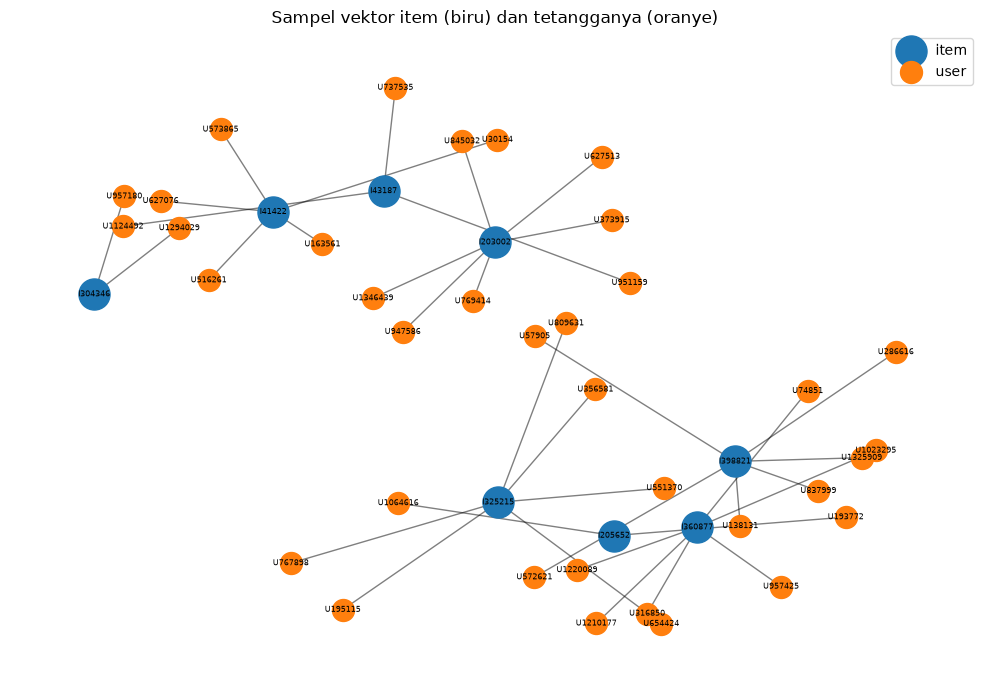

In [20]:
plot_sampel("item")

In [21]:
Xb = X.copy(); Xb.data[:] = 1                 # biner: ada atau tidak ada interaksi
deg_u = np.asarray(Xb.sum(axis=1)).ravel()    # jumlah item per user
deg_i = np.asarray(Xb.sum(axis=0)).ravel()    # jumlah user per item

print(f"User dengan 1 item saja : {(deg_u == 1).mean():.1%}")
print(f"User dengan >= 2 item   : {(deg_u >= 2).mean():.1%}")
print(f"Item dengan 1 user saja : {(deg_i == 1).mean():.1%}")
print(f"Item dengan >= 2 user   : {(deg_i >= 2).mean():.1%}")
print(f"Rata-rata user per item : {deg_i.mean():.2f} | median {np.median(deg_i):.0f} | maks {deg_i.max():.0f}")

User dengan 1 item saja : 81.3%
User dengan >= 2 item   : 18.7%
Item dengan 1 user saja : 55.4%
Item dengan >= 2 user   : 44.6%
Rata-rata user per item : 2.94 | median 1 | maks 928


No.6 Berdasarkan eksplorasi no. 4 dan 5, uraikan proyeksi manakah yang lebih baik (efektif/efisien)!

In [22]:
n_u, n_i = X.shape
biaya_UU = float((deg_i ** 2).sum())    # jumlah pasangan user-user yang mungkin terbentuk
biaya_II = float((deg_u ** 2).sum())    # jumlah pasangan item-item yang mungkin terbentuk

banding = pd.DataFrame({
    "Proyeksi": ["User-User", "Item-Item"],
    "Jumlah simpul": [n_u, n_i],
    "Matriks hasil (dense)": [f"{n_u:,} x {n_u:,}", f"{n_i:,} x {n_i:,}"],
    "Perkiraan pasangan terbentuk": [f"{biaya_UU:,.0f}", f"{biaya_II:,.0f}"],
    "Pasangan / simpul": [round(biaya_UU / n_u, 1), round(biaya_II / n_i, 1)],
})
display(banding)

,Proyeksi,Jumlah simpul,Matriks hasil (dense),Perkiraan pasangan terbentuk,Pasangan / simpul
0,User-User,160017,"160,017 x 160,017","4,048,619",25.3
1,Item-Item,79896,"79,896 x 79,896","2,474,755",31.0


In [23]:
UU = (Xb @ Xb.T).tocsr(); UU.setdiag(0); UU.eliminate_zeros()
II = (Xb.T @ Xb).tocsr(); II.setdiag(0); II.eliminate_zeros()

hasil_proyeksi = pd.DataFrame({
    "Proyeksi": ["User-User", "Item-Item"],
    "Node": [n_u, n_i],
    "Relasi (tak berarah)": [UU.nnz // 2, II.nnz // 2],
    "Density": [(UU.nnz // 2) / (n_u * (n_u - 1) / 2), (II.nnz // 2) / (n_i * (n_i - 1) / 2)],
    "Node punya tetangga": [f"{(UU.getnnz(axis=1) > 0).mean():.1%}", f"{(II.getnnz(axis=1) > 0).mean():.1%}"],
})
display(hasil_proyeksi)

,Proyeksi,Node,Relasi (tak berarah),Density,Node punya tetangga
0,User-User,160017,1855033,0.000145,81.2%
1,Item-Item,79896,1069339,0.000335,51.3%


No.7 Berdasarkan analisis no. 6, lakukan perhitungan similarity pada hasil graf yg terproyeksi dengan menggunakan Python

In [24]:
from sklearn.preprocessing import normalize

TOPK = 10
CHUNK = 2000

IV = normalize(X_item, norm="l2").tocsr()    # tiap vektor item dibuat panjang 1
IVT = IV.T.tocsr()                           # user x item

rows, cols, vals = [], [], []
for start in tqdm(range(0, IV.shape[0], CHUNK), desc="Cosine item-item"):
    blk = (IV[start:start + CHUNK] @ IVT).tocsr()      # (potongan item) x (semua item)
    for r in range(blk.shape[0]):
        a, b = blk.indptr[r], blk.indptr[r + 1]
        c, v = blk.indices[a:b], blk.data[a:b]
        m = c != (start + r)                            # buang kemiripan dengan dirinya sendiri
        c, v = c[m], v[m]
        if len(v) == 0:
            continue
        top = np.argsort(-v)[:TOPK]
        rows += [start + r] * len(top)
        cols += list(c[top])
        vals += list(v[top])

sim_df = pd.DataFrame({
    "src": item_ids[rows],
    "dst": item_ids[cols],
    "score": np.round(vals, 6),
})
sim_df.to_csv("output/item_similarity_top10.csv", index=False)
print("Pasangan tersimpan:", f"{len(sim_df):,}")
sim_df.head()

Cosine item-item:   0%|          | 0/40 [00:00<?, ?it/s]

Pasangan tersimpan: 228,770


,src,dst,score
0,6,118177,0.333333
1,6,182745,0.288675
2,6,342206,0.288675
3,6,25123,0.288675
4,6,378874,0.204124


In [25]:
n_punya_tetangga = sim_df["src"].nunique()
print(f"Item punya minimal 1 item mirip: {n_punya_tetangga:,} dari {len(item_ids):,} ({n_punya_tetangga/len(item_ids):.1%})")
print(sim_df["score"].describe())
print("\nPasangan dengan skor 1.0:", f"{(sim_df['score'] >= 0.999999).sum():,}")

Item punya minimal 1 item mirip: 41,024 dari 79,896 (51.3%)
count    228770.000000
mean          0.497090
std           0.321419
min           0.000949
25%           0.213201
50%           0.447214
75%           0.716460
max           1.000000
Name: score, dtype: float64

Pasangan dengan skor 1.0: 35,434


In [26]:
deg_item = pd.Series(deg_i, index=item_ids)           # jumlah user per item
n_tetangga = sim_df.groupby("src").size()
kandidat = n_tetangga[n_tetangga == TOPK].index        # item yang punya 10 tetangga penuh
REF_ITEM = int(deg_item.loc[kandidat].idxmax())        # yang paling populer
print("Item acuan :", REF_ITEM)
print("Jumlah user yang berinteraksi:", int(deg_item[REF_ITEM]))
print("Tetangga di Python:")
display(sim_df[sim_df["src"] == REF_ITEM].sort_values("score", ascending=False).head(5))

Item acuan : 5411
Jumlah user yang berinteraksi: 928
Tetangga di Python:


,src,dst,score
2709,5411,33030,0.233859
2710,5411,89143,0.209335
2711,5411,33956,0.148278
2712,5411,459936,0.142188
2713,5411,358234,0.090154


In [27]:
sebelum_total = run_df("MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS jumlah_similar_to")
display(sebelum_total)

Q_BEFORE = """
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item {itemId: $id})
RETURN v.visitorId AS visitor, type(r) AS relasi, i.itemId AS item
LIMIT 25
"""
before_df = run_df(Q_BEFORE, id=REF_ITEM)
before_df.head()

,jumlah_similar_to
0,0


,visitor,relasi,item
0,72742,ADDED_TO_CART,5411
1,1250521,VIEWED,5411
2,317318,VIEWED,5411
3,1013111,VIEWED,5411
4,388037,VIEWED,5411


In [28]:
Q_WRITE = """
UNWIND $rows AS row
MATCH (a:Item {itemId: row.src}), (b:Item {itemId: row.dst})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.score, s.metric = 'cosine'
"""
recs = sim_df.to_dict("records")
with driver.session(database="neo4j") as s:
    for k in tqdm(range(0, len(recs), 5000), desc="Menulis SIMILAR_TO"):
        s.run(Q_WRITE, rows=recs[k:k + 5000]).consume()

display(run_df("MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS jumlah_similar_to"))

Menulis SIMILAR_TO:   0%|          | 0/46 [00:00<?, ?it/s]

,jumlah_similar_to
0,228770


A. Tuliskan CYPHER SQL untuk mendapatkan 5 records dengan similarity tertinggi (Anda tentukan sendiri record acuannya)!

In [29]:
Q_TOP5 = """
MATCH (a:Item {itemId: $id})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS item_acuan, b.itemId AS item_mirip, s.score AS similarity
ORDER BY similarity DESC, item_mirip
LIMIT 5
"""
top5_df = run_df(Q_TOP5, id=REF_ITEM)
top5_df

,item_acuan,item_mirip,similarity
0,5411,33030,0.233859
1,5411,89143,0.209335
2,5411,33956,0.148278
3,5411,459936,0.142188
4,5411,358234,0.090154


B. Tuliskan kembali nilai similarity-similarity tersebut pada graf yang telah ada! Perlihatkan hasil querynya!

In [30]:
Q_CEK = """
MATCH (a:Item)-[s:SIMILAR_TO]->(b:Item)
RETURN count(s) AS jumlah_relasi, round(avg(s.score), 4) AS rata2_skor,
       min(s.score) AS min_skor, max(s.score) AS max_skor
"""
run_df(Q_CEK)

,jumlah_relasi,rata2_skor,min_skor,max_skor
0,228770,0.4971,0.000949,1.0


In [40]:
Q_BUKTI = """
MATCH (a:Item {itemId: $id})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS dari, type(s) AS relasi, b.itemId AS ke,
       s.score AS score, s.metric AS metric
ORDER BY score DESC, ke
LIMIT 5
"""
bukti_df = run_df(Q_BUKTI, id=REF_ITEM)
display(bukti_df)

# cocokkan dengan hasil perhitungan Python (7a)
py5 = sim_df[sim_df["src"] == REF_ITEM].sort_values("score", ascending=False).head(5)
print("Sama dengan Python:",
      bukti_df["ke"].tolist() == py5["dst"].tolist() and
      np.allclose(bukti_df["score"].values, py5["score"].values))

,dari,relasi,ke,score,metric
0,5411,SIMILAR_TO,33030,0.233859,cosine
1,5411,SIMILAR_TO,89143,0.209335,cosine
2,5411,SIMILAR_TO,33956,0.148278,cosine
3,5411,SIMILAR_TO,459936,0.142188,cosine
4,5411,SIMILAR_TO,358234,0.090154,cosine


Sama dengan Python: True


No.8 Tuliskan CYPHER SQL dan tunjukkan hasil graf-nya untuk memperlihatkan kondisi: sebelum dan sesudah perhitungan similarity!

In [31]:
sesudah_total = run_df("MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS jumlah_similar_to")

banding_graf = pd.DataFrame({
    "Kondisi": ["Sebelum", "Sesudah"],
    "Relasi SIMILAR_TO": [int(sebelum_total.iloc[0, 0]), int(sesudah_total.iloc[0, 0])],
})
display(banding_graf)

Q_DERAJAT = """
MATCH (i:Item {itemId: $id})
RETURN i.itemId AS item,
       COUNT { (i)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-() } AS relasi_dari_visitor,
       COUNT { (i)-[:SIMILAR_TO]->() } AS similar_keluar
"""
display(run_df(Q_DERAJAT, id=REF_ITEM))

,Kondisi,Relasi SIMILAR_TO
0,Sebelum,0
1,Sesudah,228770


,item,relasi_dari_visitor,similar_keluar
0,5411,1017,10


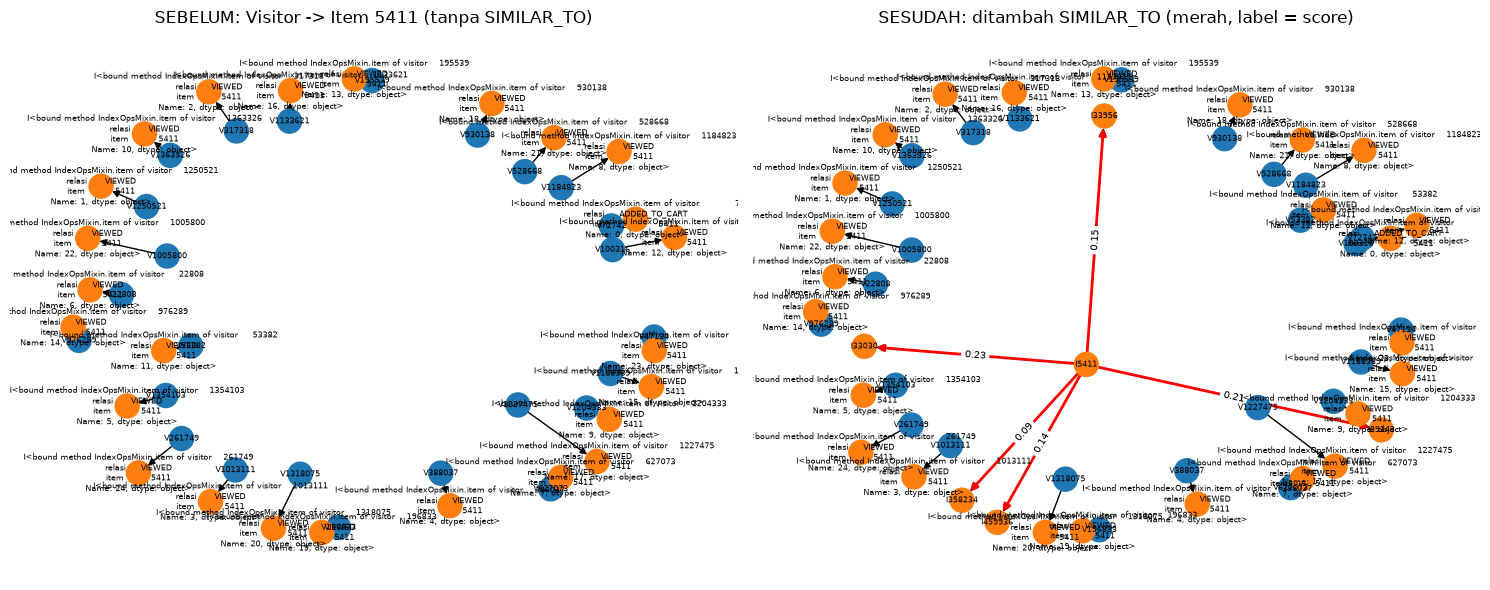

In [32]:
Q_AFTER = """
MATCH (i:Item {itemId: $id})-[s:SIMILAR_TO]->(j:Item)
RETURN i.itemId AS a, j.itemId AS b, s.score AS score
ORDER BY score DESC LIMIT 5
"""
after_sim = run_df(Q_AFTER, id=REF_ITEM)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# SEBELUM
G1 = nx.DiGraph()
for _, r in before_df.iterrows():
    G1.add_edge(f"V{r.visitor}", f"I{r.item}")
pos1 = nx.spring_layout(G1, seed=42)
warna1 = ["tab:orange" if n.startswith("I") else "tab:blue" for n in G1]
nx.draw(G1, pos1, ax=axes[0], with_labels=True, font_size=6, node_size=300, node_color=warna1)
axes[0].set_title(f"SEBELUM: Visitor -> Item {REF_ITEM} (tanpa SIMILAR_TO)")

# SESUDAH
G2 = G1.copy()
sim_edges = []
for _, r in after_sim.iterrows():
    e = (f"I{int(r.a)}", f"I{int(r.b)}")
    G2.add_edge(*e); sim_edges.append(e)
pos2 = nx.spring_layout(G2, seed=42)
warna2 = ["tab:orange" if n.startswith("I") else "tab:blue" for n in G2]
nx.draw(G2, pos2, ax=axes[1], with_labels=True, font_size=6, node_size=300, node_color=warna2)
nx.draw_networkx_edges(G2, pos2, edgelist=sim_edges, edge_color="red", width=2, ax=axes[1])
nx.draw_networkx_edge_labels(G2, pos2, ax=axes[1], font_size=7,
    edge_labels={(f"I{int(r.a)}", f"I{int(r.b)}"): f"{r.score:.2f}" for _, r in after_sim.iterrows()})
axes[1].set_title("SESUDAH: ditambah SIMILAR_TO (merah, label = score)")

plt.tight_layout()
plt.savefig("output/graf_sebelum_sesudah.png", dpi=150)
plt.show()

2.2 Analytic

No.1 Pilih seorang user secara acak (tentukan proses acak-nya, dan harus bisa di-reproduksi), lalu

In [33]:
SEED = 42
K = 5

topk = (sim_df.sort_values(["src", "score"], ascending=[True, False])
              .groupby("src").head(K))
S = sp.csr_matrix(
    (topk["score"].values,
     (topk["src"].map(iid2col).values, topk["dst"].map(iid2col).values)),
    shape=(len(item_ids), len(item_ids)),
)
print("Matriks tetangga S:", S.shape, "| non-zero:", S.nnz)

Matriks tetangga S: (79896, 79896) | non-zero: 141544


In [34]:
def rekomendasi(user_id, n=5):
    r = uid2row[user_id]
    u = X[r]                                      # vektor user (1 x item)
    skor = np.asarray((u @ S).todense()).ravel()  # sum(bobot user x similarity)
    skor[u.indices] = -np.inf                     # jangan rekomendasikan yang sudah berinteraksi
    urut = np.lexsort((-deg_i, -skor))            # skor turun; kalau seri, item lebih populer dulu
    return [(int(item_ids[t]), float(skor[t])) for t in urut[:n]
            if np.isfinite(skor[t]) and skor[t] > 0]

def item_sudah_dilihat(user_id):
    return set(item_ids[X[uid2row[user_id]].indices].tolist())

In [35]:
p2_gt = p2.groupby("visitorid")["itemid"].apply(set).to_dict()

kandidat = sorted(int(user_ids[r]) for r in np.where(deg_u >= 2)[0]
                  if int(user_ids[r]) in p2_gt)
print("Jumlah kandidat user:", f"{len(kandidat):,}")

rng = np.random.default_rng(SEED)
for idx in rng.permutation(len(kandidat)):
    target_user = kandidat[idx]
    rec5 = rekomendasi(target_user, n=5)
    relevan = p2_gt[target_user] - item_sudah_dilihat(target_user)
    if len(rec5) == 5 and len(relevan) > 0:
        break

print("User terpilih (seed =", SEED, "):", target_user)
print("Item yang dilihat di P1 :", sorted(item_sudah_dilihat(target_user)))
print("\nTop-5 rekomendasi (item, skor):")
for i, (it, sk) in enumerate(rec5, 1):
    print(f"  {i}. item {it}  skor {sk:.4f}")

print("\n>>> 3 ITEM YANG DIIKLANKAN (k = 5):")
for i, (it, sk) in enumerate(rec5[:3], 1):
    print(f"  {i}. item {it}")

Jumlah kandidat user: 876
User terpilih (seed = 42 ): 414649
Item yang dilihat di P1 : [869, 118551, 185246, 254418, 266900, 276494, 303828, 330090, 432478, 438322]

Top-5 rekomendasi (item, skor):
  1. item 186095  skor 2.3794
  2. item 433940  skor 1.4258
  3. item 449118  skor 1.4258
  4. item 454346  skor 1.4258
  5. item 465058  skor 1.4258

>>> 3 ITEM YANG DIIKLANKAN (k = 5):
  1. item 186095
  2. item 433940
  3. item 449118


No.2 Berdasarkan hasil rekomendasi Anda no. 1b Analytics, hitunglah:

In [36]:
import math

def hit_at_k(rec, rel, k=5):
    return int(any(i in rel for i in rec[:k]))

def ndcg_at_k(rec, rel, k=5):
    dcg = sum(1.0 / math.log2(pos + 2) for pos, i in enumerate(rec[:k]) if i in rel)
    idcg = sum(1.0 / math.log2(pos + 2) for pos in range(min(len(rel), k)))
    return dcg / idcg if idcg > 0 else 0.0

rec_ids = [it for it, _ in rec5]
print("Rekomendasi top-5 :", rec_ids)
print("Item relevan (P2) :", len(relevan), "item, contoh:", sorted(relevan)[:10])
print("Item cocok        :", [i for i in rec_ids if i in relevan])
print(f"\nHit@5  = {hit_at_k(rec_ids, relevan)}")
print(f"NDCG@5 = {ndcg_at_k(rec_ids, relevan):.4f}")

Rekomendasi top-5 : [186095, 433940, 449118, 454346, 465058]
Item relevan (P2) : 2 item, contoh: [174815, 314073]
Item cocok        : []

Hit@5  = 0
NDCG@5 = 0.0000


In [37]:
rng2 = np.random.default_rng(SEED)
sampel = [kandidat[i] for i in rng2.permutation(len(kandidat))[:500]]

pop = pd.Series(deg_i, index=item_ids).sort_values(ascending=False)   # baseline popularitas

H, N, Hp, Np = [], [], [], []
for u in tqdm(sampel, desc="Evaluasi"):
    seen = item_sudah_dilihat(u)
    rel = p2_gt[u] - seen
    if not rel:
        continue
    rc = [it for it, _ in rekomendasi(u, 5)]
    H.append(hit_at_k(rc, rel)); N.append(ndcg_at_k(rc, rel))
    pb = [int(i) for i in pop.index[:50] if int(i) not in seen][:5]
    Hp.append(hit_at_k(pb, rel)); Np.append(ndcg_at_k(pb, rel))

hasil = pd.DataFrame({
    "Metode": ["Item-KNN (k=5)", "Baseline popularitas"],
    "Hit@5": [np.mean(H), np.mean(Hp)],
    "NDCG@5": [np.mean(N), np.mean(Np)],
})
print("Jumlah user dievaluasi:", len(H))
hasil

Evaluasi:   0%|          | 0/500 [00:00<?, ?it/s]

Jumlah user dievaluasi: 465


,Metode,Hit@5,NDCG@5
0,Item-KNN (k=5),0.010753,0.002913
1,Baseline popularitas,0.002151,0.000282


In [38]:
skor_all = np.asarray((X[uid2row[target_user]] @ S).todense()).ravel()
for it in sorted(relevan):
    ada = it in iid2col
    print(f"item {it} | ada di P1: {ada} | skor: {skor_all[iid2col[it]]:.4f}" if ada
          else f"item {it} | ada di P1: False (cold-start)")

tot = cold = 0
for u in sampel:
    rel_u = p2_gt[u] - item_sudah_dilihat(u)
    tot += len(rel_u); cold += sum(1 for i in rel_u if i not in iid2col)
print(f"\nItem relevan 465 user: {tot}, cold-start: {cold} ({cold/tot:.1%})")

item 174815 | ada di P1: True | skor: 0.0000
item 314073 | ada di P1: True | skor: 0.5245

Item relevan 465 user: 3730, cold-start: 1343 (36.0%)


In [39]:
rel = run_df("MATCH ()-[r]->() RETURN type(r) AS t, count(r) AS c").set_index("t")["c"].to_dict()
n_vis = int(run_df("MATCH (v:Visitor) RETURN count(v) AS c").iloc[0, 0])
n_item = int(run_df("MATCH (i:Item) RETURN count(i) AS c").iloc[0, 0])

harapan = {
    "Visitor":            (n_vis, 160017),
    "Item":               (n_item, 79896),
    "VIEWED":             (rel.get("VIEWED"), 291122),
    "ADDED_TO_CART":      (rel.get("ADDED_TO_CART"), 7110),
    "BOUGHT":             (rel.get("BOUGHT"), 2331),
    "SIMILAR_TO":         (rel.get("SIMILAR_TO"), 228770),
    "non-zero X":         (X.nnz, 234959),
    "pasangan sim_df":    (len(sim_df), 228770),
    "non-zero S (k=5)":   (S.nnz, 141544),
    "kandidat user":      (len(kandidat), 876),
    "user terpilih":      (target_user, 414649),
    "item acuan":         (REF_ITEM, 5411),
    "top-5 rekomendasi":  ([it for it, _ in rec5], [186095, 433940, 449118, 454346, 465058]),
    "user dievaluasi":    (len(H), 465),
    "Hit@5 Item-KNN":     (round(float(np.mean(H)), 6), 0.010753),
    "NDCG@5 Item-KNN":    (round(float(np.mean(N)), 6), 0.002913),
    "Hit@5 baseline":     (round(float(np.mean(Hp)), 6), 0.002151),
    "NDCG@5 baseline":    (round(float(np.mean(Np)), 6), 0.000282),
}
semua_ok = True
for k, (hasil, target) in harapan.items():
    cocok = hasil == target
    semua_ok &= cocok
    print(f"{'OK  ' if cocok else 'BEDA'} {k:20s} hasil={hasil}  harapan={target}")
print("\nSEMUA SESUAI" if semua_ok else "\nAda yang berbeda, cek sel terkait")

OK   Visitor              hasil=160017  harapan=160017
OK   Item                 hasil=79896  harapan=79896
OK   VIEWED               hasil=291122  harapan=291122
OK   ADDED_TO_CART        hasil=7110  harapan=7110
OK   BOUGHT               hasil=2331  harapan=2331
OK   SIMILAR_TO           hasil=228770  harapan=228770
OK   non-zero X           hasil=234959  harapan=234959
OK   pasangan sim_df      hasil=228770  harapan=228770
OK   non-zero S (k=5)     hasil=141544  harapan=141544
OK   kandidat user        hasil=876  harapan=876
OK   user terpilih        hasil=414649  harapan=414649
OK   item acuan           hasil=5411  harapan=5411
OK   top-5 rekomendasi    hasil=[186095, 433940, 449118, 454346, 465058]  harapan=[186095, 433940, 449118, 454346, 465058]
OK   user dievaluasi      hasil=465  harapan=465
OK   Hit@5 Item-KNN       hasil=0.010753  harapan=0.010753
OK   NDCG@5 Item-KNN      hasil=0.002913  harapan=0.002913
OK   Hit@5 baseline       hasil=0.002151  harapan=0.002151
OK   NDCG@5